## import lib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Exam 1

## After the Optimisation 

In [2]:
start_path = "./debug_test1_new_boxes_detection02"  # Update this path to your new output directory
results_file = f"{start_path}/summary.csv"
ocr_file = f"{start_path}/ocr_results.csv"
# Load results
results_df = pd.read_csv(results_file)
ocr_df = pd.read_csv(ocr_file)

In [3]:
len(results_df), len(ocr_df)

(19, 19)

In [4]:
dni_zone = results_df.copy()
ocr_results = ocr_df.copy()

In [5]:
print(f"max page: {dni_zone['page'].max()}")
print(f"num unique DNI predected:{ocr_results['predicted_dni'].nunique()}")
print(f"num of duplicate predicted DNI:{ocr_results['predicted_dni'].duplicated().sum()}")

max page: 109
num unique DNI predected:19
num of duplicate predicted DNI:0


In [148]:
dni_zone.head()

,page,dni_anchor_x0,dni_anchor_y0,dni_anchor_x1,dni_anchor_y1,annotated_image,box_1,box_2,box_3,box_4,box_5,box_6,box_7,box_8,box_9
0,1,268,241,374,348,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(382, 241, 488, 348)","(488, 242, 595, 349)","(596, 243, 703, 350)","(703, 244, 809, 351)","(810, 245, 918, 352)","(918, 246, 1025, 352)","(1025, 247, 1131, 353)","(1132, 247, 1237, 354)","(1238, 248, 1345, 355)"
1,7,272,239,378,346,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(386, 239, 492, 346)","(492, 240, 600, 347)","(600, 242, 708, 348)","(708, 243, 814, 350)","(815, 244, 923, 351)","(923, 245, 1030, 352)","(1030, 246, 1136, 353)","(1136, 247, 1242, 354)","(1242, 248, 1349, 355)"
2,13,231,254,369,359,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(371, 253, 476, 359)","(477, 253, 584, 360)","(584, 254, 691, 360)","(692, 254, 798, 361)","(799, 254, 907, 361)","(907, 254, 1013, 361)","(1014, 254, 1120, 361)","(1120, 254, 1226, 361)","(1227, 254, 1334, 361)"
3,19,271,246,377,353,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(385, 246, 491, 353)","(491, 247, 598, 355)","(599, 248, 706, 355)","(706, 249, 813, 356)","(813, 250, 921, 357)","(921, 251, 1028, 358)","(1028, 251, 1134, 359)","(1135, 252, 1240, 360)","(1241, 253, 1347, 361)"
4,25,282,213,388,320,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(396, 213, 502, 320)","(502, 215, 610, 321)","(610, 216, 717, 323)","(717, 217, 824, 324)","(824, 218, 933, 325)","(933, 220, 1040, 327)","(1040, 221, 1146, 328)","(1146, 222, 1252, 329)","(1252, 223, 1359, 330)"


In [149]:
ocr_results.head()

,page,predicted_dni,prediction_digits,exception_occurred,ground_truth_dni,exact_match,best_student_dni,best_student_nombre,best_student_apellidos,best_student_ratio
0,1,474799541,474799541,False,NaN,NaN,47479954,Pablo,Gargallo Valera,0.888889
1,7,399272535,399272535,False,NaN,NaN,39937253,Izan,Lopez Macia,0.777778
2,13,482293772,482293772,False,NaN,NaN,48729372,Javier,Sánchez Flor,0.777778
3,19,218023558,218023558,False,NaN,NaN,21802355,Jorge,Garcia Cortés,0.888889
4,25,62867595,62867595,False,NaN,NaN,6286789,Emma,Sánchez Silaghi,0.750000


## Tab of the manual classification 

In [6]:
real_dni_exames = pd.read_csv("/home/ariouich/Téléchargements/202603128-exam_1/exam_1/csv/detalles.csv", sep=';')  # Load the real DNI exams data

In [7]:
real_dni_exames.head()

,ID estudiante,Apellidos,Nombre,Nota,Inicio,Fin
0,47479954,Gargallo Valera,Pablo,4.95,1,6
1,48729372,Sánchez Flor,Javier,4.45,13,18
2,39937253,Lopez Macia,Izan,6.00,7,12
3,21802355,Garcia Cortés,Jorge,7.20,19,24
4,6286789,Sánchez Silaghi,Emma,7.40,25,30


## Calculate the percentage of error after opti

In [8]:
df_true = real_dni_exames[['ID estudiante','Inicio']]
df_predected = ocr_results[['best_student_dni','page']]

In [9]:
N = len(df_true)
# Merge df_true and df_predected on 'Inicio' == 'page'
merged = pd.merge(df_true, df_predected, left_on='Inicio', right_on='page', how='inner')

# Calculate error_count as the number of mismatches
error_count = sum(merged['ID estudiante'] != merged['best_student_dni'])
accuracy = (N - error_count) / N * 100
print(f"Accuracy: {accuracy:.2f}%")

Accuracy: 84.21%


In [10]:
error_count

3

## Test befor optimisation 

In [11]:
ocr_results_befor_optimization = pd.read_csv("/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackend/CNN_HandWrittenRecognition/test/debug_test1_new/ocr_results.csv")

ocr_results_befor_optimization.head()

,page,predicted_dni,prediction_digits,exception_occurred,ground_truth_dni,exact_match,best_student_dni,best_student_nombre,best_student_apellidos,best_student_ratio
0,1,474799592,474799592,False,NaN,NaN,47479954,Pablo,Gargallo Valera,0.777778
1,7,529272532,529272532,False,NaN,NaN,39937253,Izan,Lopez Macia,0.555556
2,13,148729352,148729352,True,NaN,NaN,48729372,Javier,Sánchez Flor,0.777778
3,19,218023552,218023552,False,NaN,NaN,21802355,Jorge,Garcia Cortés,0.888889
4,25,62863895,62863895,False,NaN,NaN,6286789,Emma,Sánchez Silaghi,0.750000


In [12]:
df_predected_befor = ocr_results_befor_optimization[['best_student_dni','page']]
N = len(df_true)
# Merge df_true and df_predected on 'Inicio' == 'page'
merged_befor = pd.merge(df_true, df_predected_befor, left_on='Inicio', right_on='page', how='inner')

# Calculate error_count as the number of mismatches
error_count = sum(merged_befor['ID estudiante'] != merged_befor['best_student_dni'])
accuracy_befor = (N - error_count) / N * 100
print(f"Accuracy: {accuracy_befor:.2f}%")

Accuracy: 57.89%


In [13]:
#summarize the results
print(f"Accuracy before optimization: {accuracy_befor:.2f}%")
print(f"Accuracy after optimization: {accuracy:.2f}%")


Accuracy before optimization: 57.89%
Accuracy after optimization: 84.21%


# Exam 2

## Real result hand  annoted

In [14]:
real_exam_2 = pd.read_csv("/home/ariouich/Téléchargements/202603115-exam_2/exam_2/csv/detalles.csv", sep=';')
# Load the real DNI exams data  
df_true_exam_2 = real_exam_2[['ID estudiante','Inicio']]

## Result after optimisation

In [15]:
ocr_results_after_optimization_exam_2 = pd.read_csv("/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackend/CNN_HandWrittenRecognition/test/debug_test2_new_boxes_detection02/ocr_results.csv")
df_predected_after_optimization_exam_2 = ocr_results_after_optimization_exam_2[['best_student_dni','page']]

## Result befor optimisation

In [16]:
ocr_results_befor_optimization_exam_2 = pd.read_csv("/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackend/CNN_HandWrittenRecognition/test/debug_test2/ocr_results.csv")
df_predected_befor_optimization_exam_2 = ocr_results_befor_optimization_exam_2[['best_student_dni','page']]

## Sammury of results 

### Result after optimisation

In [17]:
N_2 = len(real_exam_2)
# Merge df_true and df_predected on 'Inicio' == 'page'
merged_after_optimization_exam_2 = pd.merge(df_true_exam_2, df_predected_after_optimization_exam_2, left_on='Inicio', right_on='page', how='inner')
# Calculate error_count as the number of mismatches
error_count_after_optimization_exam_2 = sum(merged_after_optimization_exam_2['ID estudiante'] != merged_after_optimization_exam_2['best_student_dni'].astype(str))
accuracy_after_optimization_exam_2 = (N_2 - error_count_after_optimization_exam_2) / N_2 * 100
print(f"Accuracy after optimization for exam 2: {accuracy_after_optimization_exam_2:.2f}%")

Accuracy after optimization for exam 2: 88.24%


### Result befor optimisation

In [18]:
ocr_results_befor_optimization_exam_2 = pd.read_csv("/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackend/CNN_HandWrittenRecognition/test/debug_test2/ocr_results.csv")
df_predected_befor_optimization_exam_2 = ocr_results_befor_optimization_exam_2[['best_student_dni','page']]

In [19]:
# Merge df_true and df_predected on 'Inicio' == 'page'
merged_befor_optimization_exam_2 = pd.merge(df_true_exam_2, df_predected_befor_optimization_exam_2, left_on='Inicio', right_on='page', how='inner')
# Calculate error_count as the number of mismatches
error_count_befor_optimization_exam_2 = sum(merged_befor_optimization_exam_2['ID estudiante'] != merged_befor_optimization_exam_2['best_student_dni'])
accuracy_befor_optimization_exam_2 = (N_2 - error_count_befor_optimization_exam_2) / N_2 * 100
print(f"Accuracy before optimization for exam 2: {accuracy_befor_optimization_exam_2:.2f}%")    

Accuracy before optimization for exam 2: 52.94%


## summarize the results for exam 2

In [20]:
# summarize the results for exam 2
print(f"Accuracy before optimization for exam 2: {accuracy_befor_optimization_exam_2:.2f}%")
print(f"Accuracy after optimization for exam 2: {accuracy_after_optimization_exam_2:.2f}%")

Accuracy before optimization for exam 2: 52.94%
Accuracy after optimization for exam 2: 88.24%


# Exam 3

## Real result hand  annoted

In [21]:
real_exam_3 = pd.read_csv("/home/ariouich/Téléchargements/202603128-exam_3/exam_3/csv/detalles.csv", sep=';')
df_true_exam_3 = real_exam_3[['ID estudiante','Inicio']]

## Result after optimisation

In [22]:
ocr_results_after_optimization_exam_3 = pd.read_csv("/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackend/CNN_HandWrittenRecognition/test/debug_test3_new_boxes_detection02/ocr_results.csv")
df_predected_after_optimization_exam_3 = ocr_results_after_optimization_exam_3[['best_student_dni','page']]

## Result befor optimisation

In [23]:
ocr_results_befor_optimization_exam_3 = pd.read_csv("/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackend/CNN_HandWrittenRecognition/test/debug_test3/ocr_results.csv")
df_predected_befor_optimization_exam_3 = ocr_results_befor_optimization_exam_3[['best_student_dni','page']]

## Sammury of results 

### Result after optimisation

In [24]:
N_3 = len(real_exam_3)
# Merge df_true and df_predected on 'Inicio' == 'page'
merged_after_optimization_exam_3 = pd.merge(df_true_exam_3, df_predected_after_optimization_exam_3, left_on='Inicio', right_on='page', how='inner')
# Calculate error_count as the number of mismatches
error_count_after_optimization_exam_3 = sum(merged_after_optimization_exam_3['ID estudiante'] != merged_after_optimization_exam_3['best_student_dni'])
accuracy_after_optimization_exam_3 = (N_3 - error_count_after_optimization_exam_3) / N_3 * 100
print(f"Accuracy after optimization for exam 3: {accuracy_after_optimization_exam_3:.2f}%")

Accuracy after optimization for exam 3: 90.91%


### Result befor optimisation

In [25]:
# Merge df_true and df_predected on 'Inicio' == 'page'
merged_befor_optimization_exam_3 = pd.merge(df_true_exam_3, df_predected_befor_optimization_exam_3, left_on='Inicio', right_on='page', how='inner')
# Calculate error_count as the number of mismatches
error_count_befor_optimization_exam_3 = sum(merged_befor_optimization_exam_3['ID estudiante'] != merged_befor_optimization_exam_3['best_student_dni'])
accuracy_befor_optimization_exam_3 = (N_3 - error_count_befor_optimization_exam_3) / N_3 * 100
print(f"Accuracy before optimization for exam 3: {accuracy_befor_optimization_exam_3:.2f}%")

Accuracy before optimization for exam 3: 54.55%


## summarize the results for exam 3

In [26]:
#summarize the results for exam 3
print(f"Accuracy before optimization for exam 3: {accuracy_befor_optimization_exam_3:.2f}%")
print(f"Accuracy after optimization for exam 3: {accuracy_after_optimization_exam_3:.2f}%")

Accuracy before optimization for exam 3: 54.55%
Accuracy after optimization for exam 3: 90.91%


# statistc of our exp

In [27]:
# create a table summarizing the results for all three exams
summary_table = pd.DataFrame({
    'Exam': ['Exam 1', 'Exam 2', 'Exam 3'],
    'Accuracy Before Optimization (%)': [accuracy_befor, accuracy_befor_optimization_exam_2, accuracy_befor_optimization_exam_3],
    'Accuracy After Optimization (%)': [accuracy, accuracy_after_optimization_exam_2, accuracy_after_optimization_exam_3]       
})

In [28]:
summary_table

,Exam,Accuracy Before Optimization (%),Accuracy After Optimization (%)
0,Exam 1,57.894737,84.210526
1,Exam 2,52.941176,88.235294
2,Exam 3,54.545455,90.909091


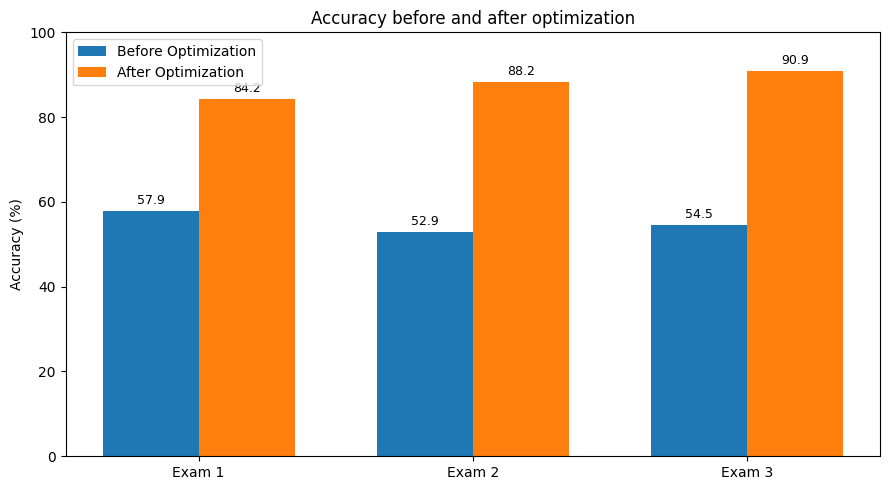

In [29]:
exam_labels = summary_table['Exam'].tolist()
before = summary_table['Accuracy Before Optimization (%)'].astype(float).tolist()
after = summary_table['Accuracy After Optimization (%)'].astype(float).tolist()

x = list(range(len(exam_labels)))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar([xi - width / 2 for xi in x], before, width, label='Before Optimization', color='tab:blue')
ax.bar([xi + width / 2 for xi in x], after, width, label='After Optimization', color='tab:orange')

ax.set_xticks(x)
ax.set_xticklabels(exam_labels)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Accuracy before and after optimization')
ax.set_ylim(0, 100)
ax.legend()

for i, (b, a) in enumerate(zip(before, after)):
    ax.text(i - width / 2, b + 1, f"{b:.1f}", ha='center', va='bottom', fontsize=9)
    ax.text(i + width / 2, a + 1, f"{a:.1f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


Before Optimization -> mean: 55.12712261938268  variance: 6.388193399736435  std: 2.5274875666828582
After Optimization  -> mean: 87.78497044750914  variance: 11.369785458572785  std: 3.3719112471375614


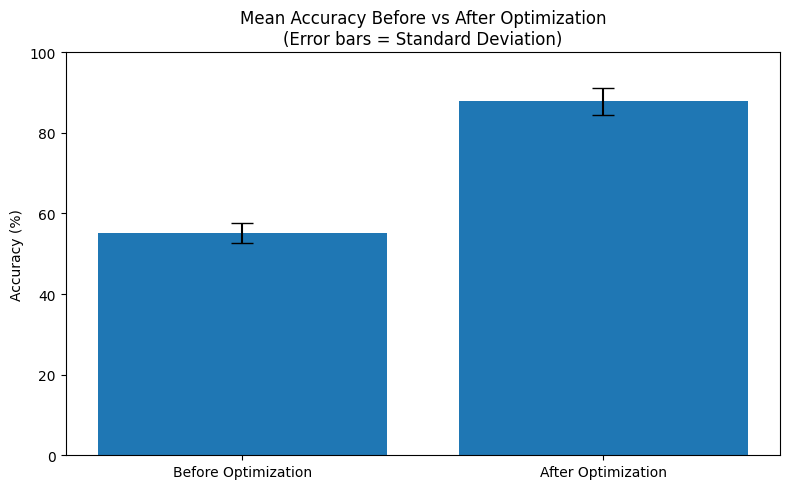

In [30]:
# Ton tableau
df = summary_table

# Colonnes
before = df["Accuracy Before Optimization (%)"]
after = df["Accuracy After Optimization (%)"]

# Calculs
means = [before.mean(), after.mean()]
variances = [before.var(ddof=1), after.var(ddof=1)]
stds = [before.std(ddof=1), after.std(ddof=1)]

# Résumé console
print("Before Optimization -> mean:", means[0], " variance:", variances[0], " std:", stds[0])
print("After Optimization  -> mean:", means[1], " variance:", variances[1], " std:", stds[1])

# Plot
labels = ["Before Optimization", "After Optimization"]

plt.figure(figsize=(8,5))
plt.bar(labels, means, yerr=stds, capsize=8)
plt.ylabel("Accuracy (%)")
plt.title("Mean Accuracy Before vs After Optimization\n(Error bars = Standard Deviation)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [31]:
"""import json

REF_PATH = "/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/transfer_279434_files_ec8e0eac/FCO_11542_2024.csv"
OUT_JSON_PATH = "/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/transfer_279434_files_ec8e0eac/FCO_11542_2024.json"

df_ref = pd.read_csv(REF_PATH)

def get_value(record, keys, default=""):
    for key in keys:
        if key in record and pd.notna(record[key]):
            return record[key]
    return default

students = []
for record in df_ref.to_dict(orient="records"):
    students.append({
        "dni": str(get_value(record, ["dni", "DNI", "Dni", "documento", "numero"])).strip(),
        "nombre": str(get_value(record, ["nombre", "Nombre", "first_name", "prenom"])).strip(),
        "apellidos": str(get_value(record, ["apellidos", "Apellidos", "apellido", "Apellido", "last_name"])).strip(),
    })

with open(OUT_JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(students, f, ensure_ascii=False, indent=2)

print(f"Écrit {len(students)} enregistrements dans {OUT_JSON_PATH}")"""

'import json\n\nREF_PATH = "/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/transfer_279434_files_ec8e0eac/FCO_11542_2024.csv"\nOUT_JSON_PATH = "/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/transfer_279434_files_ec8e0eac/FCO_11542_2024.json"\n\ndf_ref = pd.read_csv(REF_PATH)\n\ndef get_value(record, keys, default=""):\n    for key in keys:\n        if key in record and pd.notna(record[key]):\n            return record[key]\n    return default\n\nstudents = []\nfor record in df_ref.to_dict(orient="records"):\n    students.append({\n        "dni": str(get_value(record, ["dni", "DNI", "Dni", "documento", "numero"])).strip(),\n        "nombre": str(get_value(record, ["nombre", "Nombre", "first_name", "prenom"])).strip(),\n        "apellidos": str(get_value(record, ["apellidos", "Apellidos", "apellido", "Apellido", "last_name"])).strip(),\n    })\n\nwith open(OUT_JSON_PATH, "w", encoding="utf-8") as f:\n    json.dump(students, f, ensure_ascii=False, indent=2)\n\nprint(f"Écr

## Nez exames 
# exam 4

In [32]:
path_exam_4 = "/home/ariouich/Téléchargements/exam4/N1/csv/detalles.csv"
path_exam_4_ocr_results = "/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackend/CNN_HandWrittenRecognition/test/debug_test4_new_boxes_detection03/ocr_results.csv"

In [33]:
real_exam_4 = pd.read_csv(path_exam_4, sep=';')
df_true_exam_4 = real_exam_4[['ID estudiante','Inicio']]
ocr_results_exam_4 = pd.read_csv(path_exam_4_ocr_results)
df_predected_exam_4 = ocr_results_exam_4[['best_student_dni','page']]

In [34]:
N_4 = len(real_exam_4)
# Merge df_true and df_predected on 'Inicio' == 'page'
merged_after_optimization_exam_4 = pd.merge(df_true_exam_4, df_predected_exam_4, left_on='Inicio', right_on='page', how='inner')
# Calculate error_count as the number of mismatches
error_count_after_optimization_exam_4 = sum(merged_after_optimization_exam_4['ID estudiante'] != merged_after_optimization_exam_4['best_student_dni'].astype(str))
accuracy_after_optimization_exam_4 = (N_4 - error_count_after_optimization_exam_4) / N_4 * 100
print(f"Accuracy after optimization for exam 4: {accuracy_after_optimization_exam_4:.2f}%")

Accuracy after optimization for exam 4: 40.00%


In [35]:
ordered_df_exam_1 = df_true.sort_values(by='Inicio').reset_index(drop=True)
ordered_predicted_exam_1 = df_predected.sort_values(by='page').reset_index(drop=True)
error_count_first_page_exam_1 = sum(ordered_df_exam_1["Inicio"] != ordered_predicted_exam_1["page"])
accuracy_first_page_exam_1 = (len(ordered_df_exam_1) - error_count_first_page_exam_1) / len(ordered_df_exam_1) * 100
print(f"Accuracy for the first page of exam 1: {accuracy_first_page_exam_1:.2f}%")

ordered_df_exam_2 = df_true_exam_2.sort_values(by='Inicio').reset_index(drop=True)
ordered_predicted_exam_2 = df_predected_after_optimization_exam_2.sort_values(by='page').reset_index(drop=True)
error_count_first_page_exam_2 = sum(ordered_df_exam_2["Inicio"] != ordered_predicted_exam_2["page"])
accuracy_first_page_exam_2 = (len(ordered_df_exam_2) - error_count_first_page_exam_2) / len(ordered_df_exam_2) * 100
print(f"Accuracy for the first page of exam 2: {accuracy_first_page_exam_2:.2f}%")

ordered_df_exam_3 = df_true_exam_3.sort_values(by='Inicio').reset_index(drop=True)
ordered_predicted_exam_3 = df_predected_after_optimization_exam_3.sort_values(by='page').reset_index(drop=True)
error_count_first_page_exam_3 = sum(ordered_df_exam_3["Inicio"] != ordered_predicted_exam_3["page"])
accuracy_first_page_exam_3 = (len(ordered_df_exam_3) - error_count_first_page_exam_3) / len(ordered_df_exam_3) * 100
print(f"Accuracy for the first page of exam 3: {accuracy_first_page_exam_3:.2f}%")



Accuracy for the first page of exam 1: 100.00%
Accuracy for the first page of exam 2: 100.00%
Accuracy for the first page of exam 3: 100.00%


In [36]:
ordered_df_exam_1_befor = df_true.sort_values(by='Inicio').reset_index(drop=True)
ordered_predicted_exam_1_befor = df_predected_befor.sort_values(by='page').reset_index(drop=True)
N_1_pages = len(ordered_df_exam_1_befor)
N_1_pages_predected = len(ordered_predicted_exam_1_befor)
N_hallucinated = N_1_pages_predected - N_1_pages
print(f"Number of pages in the first page of exam 1: {N_1_pages}")
print(f"Number of pages predected in the first page of exam 1: {N_1_pages_predected}")
print(f"Number of hallucinated pages in the first page of exam 1: {N_hallucinated}")
Precision = (N_1_pages_predected - N_hallucinated) / N_1_pages_predected * 100 if N_1_pages_predected > 0 else 0
Recall = (N_1_pages - N_hallucinated) / N_1_pages * 100 if N_1_pages > 0 else 0
print(f"Precision for the first page of exam 1: {Precision:.2f}%")
print(f"Recall for the first page of exam 1: {Recall:.2f}%")
accuracy_first_page_exam_1_befor =  (Recall * Precision) / (Recall + Precision) 
print(f"F1 Score for the first page of exam 1 before optimization: {accuracy_first_page_exam_1_befor:.2f}%")

Number of pages in the first page of exam 1: 19
Number of pages predected in the first page of exam 1: 33
Number of hallucinated pages in the first page of exam 1: 14
Precision for the first page of exam 1: 57.58%
Recall for the first page of exam 1: 26.32%
F1 Score for the first page of exam 1 before optimization: 18.06%


In [37]:
def calculate_metrics(Y_real, Y_pred, option = "pages"):
   N = len(Y_real)
   N_pred = len(Y_pred)
   hall = N_pred - N
   Metric = None
   if option == "pages":
       ordered_Y_real = Y_real.sort_values(by='Inicio').reset_index(drop=True)
       ordered_Y_pred = Y_pred.sort_values(by='page').reset_index(drop=True)
       N_real = N
       N_pred = N_pred
       N_hallucinated = hall
       Precision = (N_pred - N_hallucinated) / N_pred * 100
       Recall = (N_real - N_hallucinated) / N_real * 100
       F1_Score = 2*(Recall * Precision) / (Recall + Precision) 
       Metric = {"Precision": f"{Precision:.2f}%", "Recall": f"{Recall:.2f}%", "F1_Score": f"{F1_Score:.2f}%"}
   elif option == "DNI":
       merged = pd.merge(Y_real, Y_pred, left_on='Inicio', right_on='page', how='inner')
       error_count = sum(merged['ID estudiante'].astype(str) != merged['best_student_dni'].astype(str))
       accuracy = (N - (error_count )) / N * 100 
       Metric = {"Accuracy": f"{accuracy:.2f}%"}
       if accuracy < 50 : 
              print("Warning: Accuracy is below 50%, which may indicate a problem with the OCR results or the matching process.")
              print( merged[merged['ID estudiante'].astype(str) != merged['best_student_dni'].astype(str)])
   return Metric 
  
       

In [38]:
print( f"For the detection of pages before optimization exam 1: {calculate_metrics(ordered_df_exam_1_befor, ordered_predicted_exam_1_befor, option='pages')}")
print( f"For the detection of pages after optimization exam 1: {calculate_metrics(ordered_df_exam_1, ordered_predicted_exam_1, option='pages')}")
print( f"For the detection of DNI after optimization exam 1: {calculate_metrics(ordered_df_exam_1, ordered_predicted_exam_1, option='DNI')}")
print( f"For the detection of DNI exam 1: {calculate_metrics(ordered_df_exam_1, df_predected_befor, option='DNI')}")

For the detection of pages before optimization exam 1: {'Precision': '57.58%', 'Recall': '26.32%', 'F1_Score': '36.12%'}
For the detection of pages after optimization exam 1: {'Precision': '100.00%', 'Recall': '100.00%', 'F1_Score': '100.00%'}
For the detection of DNI after optimization exam 1: {'Accuracy': '84.21%'}
For the detection of DNI exam 1: {'Accuracy': '57.89%'}


In [39]:
print(f"For the detection of pages before optimization exam 2: {calculate_metrics(ordered_df_exam_2, ordered_predicted_exam_2, option='pages')}")
print(f"For the detection of pages after optimization exam 2: {calculate_metrics(ordered_df_exam_2, ordered_predicted_exam_2, option='pages')}")
print(f"For the detection of DNI after optimization exam 2: {calculate_metrics(df_true_exam_2, df_predected_after_optimization_exam_2, option='DNI')}")
print(f"For the detection of DNI before optimization exam 2: {calculate_metrics(df_true_exam_2, df_predected_befor_optimization_exam_2, option='DNI')}")
print(f"For the detection of pages before optimization exam 3: {calculate_metrics(ordered_df_exam_3, ordered_predicted_exam_3, option='pages')}")
print(f"For the detection of pages after optimization exam 3: {calculate_metrics(ordered_df_exam_3, ordered_predicted_exam_3, option='pages')}")
print(f"For the detection of DNI after optimization exam 3: {calculate_metrics(df_true_exam_3, df_predected_after_optimization_exam_3, option='DNI')}")
print(f"For the detection of DNI before optimization exam 3: {calculate_metrics(df_true_exam_3, df_predected_befor_optimization_exam_3, option='DNI')}")

For the detection of pages before optimization exam 2: {'Precision': '100.00%', 'Recall': '100.00%', 'F1_Score': '100.00%'}
For the detection of pages after optimization exam 2: {'Precision': '100.00%', 'Recall': '100.00%', 'F1_Score': '100.00%'}
For the detection of DNI after optimization exam 2: {'Accuracy': '88.24%'}
For the detection of DNI before optimization exam 2: {'Accuracy': '52.94%'}
For the detection of pages before optimization exam 3: {'Precision': '100.00%', 'Recall': '100.00%', 'F1_Score': '100.00%'}
For the detection of pages after optimization exam 3: {'Precision': '100.00%', 'Recall': '100.00%', 'F1_Score': '100.00%'}
For the detection of DNI after optimization exam 3: {'Accuracy': '90.91%'}
For the detection of DNI before optimization exam 3: {'Accuracy': '54.55%'}


In [40]:
ordered_df_exam_4 = df_true_exam_4.sort_values(by='Inicio').reset_index(drop=True)
ordered_predicted_exam_4 = df_predected_exam_4.sort_values(by='page').reset_index(drop=True)

print(f"For the detection of pages after optimization exam 4: {calculate_metrics(ordered_df_exam_4, ordered_predicted_exam_4, option='pages')}")
print(f"For the detection of DNI after optimization exam 4: {calculate_metrics(df_true_exam_4, df_predected_exam_4, option='DNI')}")

For the detection of pages after optimization exam 4: {'Precision': '100.00%', 'Recall': '100.00%', 'F1_Score': '100.00%'}
   ID estudiante  Inicio  best_student_dni  page
1       48832871      10          44533727    10
3       54946260      26          54556604    26
4       21803481      34          73478334    34
5       27365982      42          24552726    42
6       20946619      50          20940061    50
10      48261887      98          24522114    98
11      23945866      82          23873855    82
12      26883274     106          44533727   106
15      23887869     122          21704636   122
16      73599670     130          73102736   130
18      54557162     154          24552726   154
19      49600382     146          24552726   146
21      49468081     162          44946021   162
22       Y769098     185           4632380   185
23      44928654     201          54942590   201
25      58002926     193          24552726   193
26      49358921     170          24552726  

In [41]:
#test 5
path_exam_5 = "/home/ariouich/Téléchargements/202604106-Exam5/Exam5/csv/detalles.csv"
path_exam_5_ocr_results = "/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackend/CNN_HandWrittenRecognition/test/debug_test5_new_boxes_detection02/ocr_results.csv"
real_exam_5 = pd.read_csv(path_exam_5, sep=';')
df_true_exam_5 = real_exam_5[['ID estudiante','Inicio']]
ocr_results_exam_5 = pd.read_csv(path_exam_5_ocr_results)
df_predected_exam_5 = ocr_results_exam_5[['best_student_dni','page']]

In [42]:
print(f"For the detection of pages after optimization exam 5: {calculate_metrics(df_true_exam_5, df_predected_exam_5, option='pages')}")
print(f"For the detection of DNI after optimization exam 5: {calculate_metrics(df_true_exam_5, df_predected_exam_5, option='DNI')}")

For the detection of pages after optimization exam 5: {'Precision': '100.00%', 'Recall': '100.00%', 'F1_Score': '100.00%'}
    ID estudiante  Inicio  best_student_dni  page
1        24442854       9          44923594     9
3        17534236      25          77545974    25
6        49906094      49          23323871    49
7        29216894      65          49265345    65
8         4262967      57          24521757    57
10       26660163      81          24522114    81
11       54016402      89          21004124    89
12       23323871     121          44533727   121
15       54878682     105          49252205   105
For the detection of DNI after optimization exam 5: {'Accuracy': '43.75%'}


# after a nother modiffication 

In [43]:
df_predected_after_2optimization_exam_1 = pd.read_csv("/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackend/CNN_HandWrittenRecognition/test/debug_test1_new_boxes_detection06/ocr_results.csv")[['best_student_dni','page']]

In [44]:
print(f"For the detection of pages after optimization exam 1: {calculate_metrics(df_true, df_predected_after_2optimization_exam_1, option='pages')}")
print(f"For the detection of DNI after optimization exam 1: {calculate_metrics(df_true, df_predected_after_2optimization_exam_1, option='DNI')}")

For the detection of pages after optimization exam 1: {'Precision': '100.00%', 'Recall': '100.00%', 'F1_Score': '100.00%'}
For the detection of DNI after optimization exam 1: {'Accuracy': '84.21%'}


# DNI of student Stat


In [45]:
df = pd.read_csv(
    "/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/P1_nov_para_jefferson/students_list.csv",
    encoding='latin-1',
    sep=';'
)


In [46]:
df.head()

,DNI,Nombre,Grupo,Titulación,Tipo de Matrícula,Convocatoria,Comentario Profesor,Condición,Nota final,Nota sin restricciones,...,Rec. P2,Rec. P1,Parcial 2,Parcial 1,CT_01,Poliformat (sobre 10),Prácticas (sobre 10),Retornables (sobre 10),ACTA,Unnamed: 21
0,20851815,"Abril Revert, Borja",1PARS3,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,"9,38","9,38",...,NaN,NaN,"9,1","9,25",NaN,"9,84",10,"9,81","9,4",NaN
1,26665047,"Abu-Taha Sabsoub, Nader",B1,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,"5,9","5,9",...,NaN,NaN,"5,55","5,05",NaN,"7,14","8,94","4,34","5,9",NaN
2,49570057,"Acedo Marzo, Unai",B2,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,6,6,...,NaN,NaN,"3,8","6,9",NaN,"7,65","8,29","8,04",6,NaN
3,73606454,"Agustina García, Sol",A3,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,4,"4,71",...,NaN,NaN,"2,85","5,3",NaN,"6,76","6,48","6,71",4,NaN
4,51780631,"Ahuir Botella, Pau",A1,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,"7,58","7,58",...,NaN,NaN,"6,35","8,55",NaN,"6,82","9,9","6,89","7,6",NaN


In [47]:
print(f"Forme: {df.shape}")

Forme: (260, 22)


In [48]:
dni_liste = df['DNI'].astype(str).tolist()
print(f"Unique DNI in students list: {len(set(dni_liste))}")

Unique DNI in students list: 260


In [49]:
df.drop(df.index[-1], inplace=True)

In [50]:
dni_chars = df['DNI'].astype(str).apply(lambda x: list(x))
dni_chars = pd.DataFrame(dni_chars.tolist(), index=df.index).add_prefix('DNI_char_')



In [51]:
df['DNI'].astype(str).apply(lambda x: list(x))

0      [2, 0, 8, 5, 1, 8, 1, 5]
1      [2, 6, 6, 6, 5, 0, 4, 7]
2      [4, 9, 5, 7, 0, 0, 5, 7]
3      [7, 3, 6, 0, 6, 4, 5, 4]
4      [5, 1, 7, 8, 0, 6, 3, 1]
                 ...           
254    [2, 7, 3, 6, 9, 0, 3, 3]
255       [Z, 8, 0, 7, 4, 2, 4]
256    [X, 7, 4, 7, 0, 6, 6, 4]
257    [5, 3, 9, 4, 7, 7, 5, 7]
258    [2, 4, 4, 2, 1, 0, 1, 0]
Name: DNI, Length: 259, dtype: object

In [52]:
print(dni_chars)

    DNI_char_0 DNI_char_1 DNI_char_2 DNI_char_3 DNI_char_4 DNI_char_5  \
0            2          0          8          5          1          8   
1            2          6          6          6          5          0   
2            4          9          5          7          0          0   
3            7          3          6          0          6          4   
4            5          1          7          8          0          6   
..         ...        ...        ...        ...        ...        ...   
254          2          7          3          6          9          0   
255          Z          8          0          7          4          2   
256          X          7          4          7          0          6   
257          5          3          9          4          7          7   
258          2          4          4          2          1          0   

    DNI_char_6 DNI_char_7 DNI_char_8 DNI_char_9  
0            1          5        NaN        NaN  
1            4         

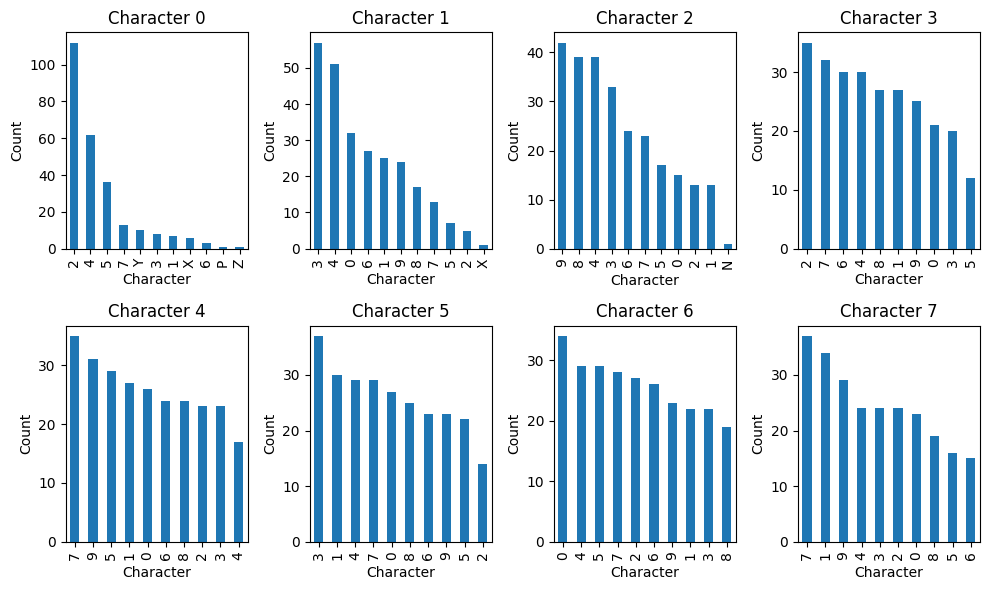

In [53]:
# make a histogram of the character of students per DNI character
plt.figure(figsize=(10, 6)) 
for i in range(8):  # Assuming DNI has 8 characters
    plt.subplot(2, 4, i + 1)
    dni_chars[f'DNI_char_{i}'].value_counts().plot(kind='bar')
    plt.title(f'Character {i}')
    plt.xlabel('Character')
    plt.ylabel('Count')
plt.tight_layout()
plt.show()

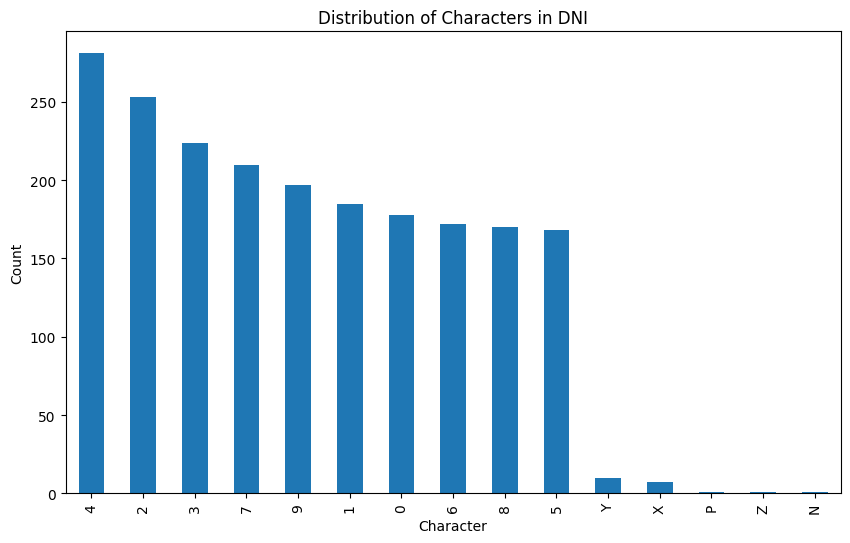

In [54]:
# histogram of destribution of the caracters in DNI 
plt.figure(figsize=(10, 6))
# Collect all characters from DNI_char_0 to DNI_char_7
all_chars = pd.concat([dni_chars[f'DNI_char_{i}'] for i in range(8)])

# Plot the grouped histogram
all_chars.value_counts().plot(kind='bar', figsize=(10, 6))
plt.title('Distribution of Characters in DNI')
plt.xlabel('Character')
plt.ylabel('Count')
plt.show()

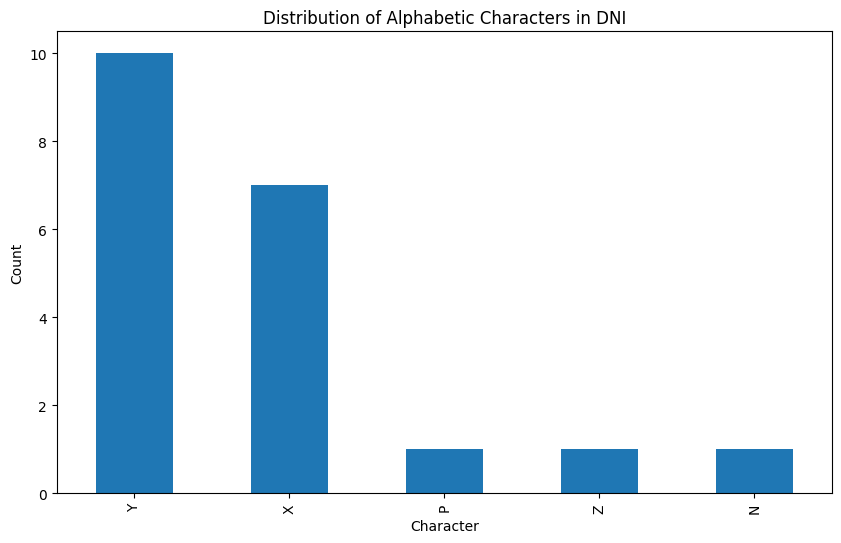

In [55]:
# Plot the distribution only the alphanumeric  characters in DNI
plt.figure(figsize=(10, 6))
# Filter out numeric characters, keep only alphabetic
alpha_chars = all_chars[all_chars.str.isalpha()]
alpha_chars.value_counts().plot(kind='bar', figsize=(10, 6))
plt.title('Distribution of Alphabetic Characters in DNI')
plt.xlabel('Character')
plt.ylabel('Count')
plt.show()

# to creat the fuction 

In [56]:
class DNIProcessor:
    def __init__(self, students_csv_path):
        self.df = pd.read_csv(
            students_csv_path,
            encoding="latin-1",
            sep=";",
            dtype={"DNI": str}
        )

        # Supprimer la dernière ligne si elle est vraiment invalide
        self.df.drop(self.df.index[-1], inplace=True)

        self.dictionary = {
            "Reste": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22],
            "Lettre": ['T', 'R', 'W', 'A', 'G', 'M', 'Y', 'F', 'P', 'D', 'X', 'B', 'N', 'J', 'Z', 'S', 'Q', 'V', 'H', 'L', 'C', 'K', 'E']
        }

        self.NIF_detection_dict = {
            "Lettre": ['X', 'Y', 'Z', 'N', 'P'],
            "Valeur": [0, 1, 2, 3, 4]
        }

    # ============================================================
    # Fonction de nettoyage
    # ============================================================
    def clean_identifier(self, value):
        """
        Nettoie un DNI/NIF :
        - supprime les espaces
        - supprime les tirets
        - met en majuscule
        """

        if pd.isna(value):
            return ""

        return str(value).strip().upper().replace(" ", "").replace("-", "")

    # ============================================================
    # Détection DNI / NIF / ERASMUS
    # ============================================================
    def detect_nif(self, dni_nif):
        """
        Détecte si l'identifiant est :
        - DNI
        - NIF
        - ERASMUS
        """

        dni_nif = self.clean_identifier(dni_nif)

        if len(dni_nif) == 0 or dni_nif == "NAN":
            raise ValueError("DNI/NIF cannot be empty")

        if len(dni_nif) > 9 and dni_nif[0].isalpha():
            return "ERASMUS"

        if dni_nif[0].isalpha():
            return "NIF"

        if dni_nif[0].isdigit():
            return "DNI"

        raise ValueError("Invalid DNI/NIF format")

    # ============================================================
    # Calcul de la lettre DNI
    # ============================================================
    def calculate_expected_letter(self, numeric_part):
        """
        Calcule la lettre attendue avec l'algorithme DNI :
        reste = numeric_part % 23
        lettre = table[reste]
        """

        reste = int(numeric_part) % 23
        return self.dictionary["Lettre"][reste]

    # ============================================================
    # Transformation de la première lettre NIF en chiffre
    # ============================================================
    def transform_nif_first_letter_to_number(self, first_letter):
        """
        Transforme la première lettre du NIF selon le dictionnaire :

        X -> 0
        Y -> 1
        Z -> 2
        N -> 3
        P -> 4
        """

        first_letter = first_letter.upper()

        if first_letter not in self.NIF_detection_dict["Lettre"]:
            raise ValueError("Invalid NIF first letter")

        index = self.NIF_detection_dict["Lettre"].index(first_letter)
        return self.NIF_detection_dict["Valeur"][index]

    # ============================================================
    # Extraction des parties du NIF
    # ============================================================
    def extract_nif_parts(self, nif):
        """
        Extrait :
        - la première lettre
        - la partie numérique
        - la lettre finale si elle existe

        Exemples :
        X7470664B -> X, 7470664, B
        X7470664  -> X, 7470664, None
        """

        nif = self.clean_identifier(nif)

        if len(nif) < 2:
            raise ValueError("Invalid NIF format")

        first_letter = nif[0]

        if first_letter not in self.NIF_detection_dict["Lettre"]:
            raise ValueError("Invalid NIF first letter")

        # Cas avec lettre finale : X7470664B
        if nif[-1].isalpha():
            numeric_part_str = nif[1:-1]
            current_letter = nif[-1]

        # Cas sans lettre finale : X7470664
        else:
            numeric_part_str = nif[1:]
            current_letter = None

        if not numeric_part_str.isdigit():
            raise ValueError("Invalid NIF numeric part")

        return first_letter, numeric_part_str, current_letter

    # ============================================================
    # Calcul de la partie numérique du NIF selon ta formule
    # ============================================================
    def calculate_nif_numeric_part(self, nif):
        """
        Calcule la partie numérique du NIF avec ta logique :

        NIF = lettre_debut + partie_numérique + lettre_finale

        X -> 0
        Y -> 1
        Z -> 2
        N -> 3
        P -> 4

        Numeric_Part = valeur_lettre * 100000000 + partie_numérique
        """

        first_letter, numeric_part_str, current_letter = self.extract_nif_parts(nif)

        first_letter_number = self.transform_nif_first_letter_to_number(first_letter)

        numeric_part = first_letter_number * 10**len(numeric_part_str) + int(numeric_part_str)

        return numeric_part

    # ============================================================
    # Traitement d'un DNI
    # ============================================================
    def process_dni(self, dni):
        """
        Traite un DNI avec ou sans lettre.

        Exemples :
        12345678Z
        12345678
        """

        dni = self.clean_identifier(dni)

        # Cas DNI sans lettre : 12345678
        if dni.isdigit():
            numeric_part = int(dni)
            current_letter = None
            expected_letter = self.calculate_expected_letter(numeric_part)
            expected_id = dni + expected_letter
            is_valid = None

        # Cas DNI avec lettre : 12345678Z
        elif dni[:-1].isdigit() and dni[-1].isalpha():
            numeric_part = int(dni[:-1])
            current_letter = dni[-1]
            expected_letter = self.calculate_expected_letter(numeric_part)
            expected_id = dni[:-1] + expected_letter
            is_valid = current_letter == expected_letter

        else:
            raise ValueError("Invalid DNI format")

        return {
            "Numeric_Part": numeric_part,
            "Current_Letter": current_letter,
            "Expected_Letter": expected_letter,
            "Expected_ID": expected_id,
            "Is_Valid": is_valid
        }

    # ============================================================
    # Traitement d'un NIF
    # ============================================================
    def process_nif(self, nif):
        """
        Traite un NIF avec ou sans lettre finale.

        La logique utilisée est :

        Numeric_Part = valeur_lettre_debut * 100000000 + partie_numérique
        Expected_Letter = Lettre[Numeric_Part % 23]
        """

        nif = self.clean_identifier(nif)

        first_letter, numeric_part_str, current_letter = self.extract_nif_parts(nif)

        numeric_part = self.calculate_nif_numeric_part(nif)

        expected_letter = self.calculate_expected_letter(numeric_part)

        expected_id = first_letter + numeric_part_str + expected_letter

        if current_letter is None:
            is_valid = None
        else:
            is_valid = current_letter == expected_letter

        return {
            "Numeric_Part": numeric_part,
            "Current_Letter": current_letter,
            "Expected_Letter": expected_letter,
            "Expected_ID": expected_id,
            "Is_Valid": is_valid
        }

    # ============================================================
    # Filtrer les lignes DNI / NIF / ERASMUS
    # ============================================================
    def find_rows_DNI_or_NIF(self, id_type: str):
        id_type = str(id_type).strip().upper()

        if id_type not in {"DNI", "NIF", "ERASMUS"}:
            raise ValueError("id_type must be 'DNI', 'NIF', or 'ERASMUS'")

        ids = self.df["DNI"].apply(self.detect_nif)

        return self.df[ids == id_type]

    # ============================================================
    # Algorithme pour DNI uniquement
    # ============================================================
    def get_the_alphabatic_caracters_algorithm(self):
        """
        Calcule la lettre attendue pour les DNI.

        Retourne :
        DNI, Numeric_Part, Expected_Letter
        """

        results = []

        for raw_id in self.df["DNI"]:
            try:
                clean_id = self.clean_identifier(raw_id)

                if self.detect_nif(clean_id) != "DNI":
                    continue

                dni_result = self.process_dni(clean_id)

                results.append({
                    "DNI": clean_id,
                    "Numeric_Part": dni_result["Numeric_Part"],
                    "Expected_Letter": dni_result["Expected_Letter"]
                })

            except Exception:
                continue

        return pd.DataFrame(results)

    # ============================================================
    # Algorithme pour NIF uniquement
    # ============================================================
    def get_the_alphabatic_caracters_algorithm_for_nif(self):
        """
        Calcule la lettre attendue pour les NIF.

        Retourne uniquement :
        - DNI : le NIF original
        - Numeric_Part : la partie numérique calculée
        - Expected_Letter : la lettre attendue selon le tableau DNI
        """

        results = []

        for raw_id in self.df["DNI"]:
            try:
                clean_id = self.clean_identifier(raw_id)

                if self.detect_nif(clean_id) != "NIF":
                    continue

                numeric_part = self.calculate_nif_numeric_part(clean_id)
                expected_letter = self.calculate_expected_letter(numeric_part)

                results.append({
                    "DNI": clean_id,
                    "Numeric_Part": numeric_part,
                    "Expected_Letter": expected_letter
                })

            except Exception:
                results.append({
                    "DNI": self.clean_identifier(raw_id),
                    "Numeric_Part": None,
                    "Expected_Letter": None
                })

        return pd.DataFrame(results)[["DNI", "Numeric_Part", "Expected_Letter"]]

    # ============================================================
    # Fonction principale
    # ============================================================
    def dni_processing(self):
        """
        Fonction principale de traitement.

        Elle utilise :
        - detect_nif()
        - process_dni()
        - process_nif()
        - calculate_expected_letter()
        - calculate_nif_numeric_part()

        Elle retourne le DataFrame original enrichi avec :
        - Original_ID
        - ID_Type
        - Normalized_ID
        - Numeric_Part
        - Current_Letter
        - Expected_Letter
        - Expected_ID
        - Is_Valid
        - Error
        """

        results = []

        for index, raw_id in self.df["DNI"].items():
            row_result = {
                "Original_ID": raw_id,
                "ID_Type": None,
                "Normalized_ID": None,
                "Numeric_Part": None,
                "Current_Letter": None,
                "Expected_Letter": None,
                "Expected_ID": None,
                "Is_Valid": None,
                "Error": None
            }

            try:
                clean_id = self.clean_identifier(raw_id)

                if len(clean_id) == 0:
                    raise ValueError("Empty DNI/NIF")

                id_type = self.detect_nif(clean_id)

                row_result["ID_Type"] = id_type
                row_result["Normalized_ID"] = clean_id

                # =========================
                # CAS ERASMUS
                # =========================
                if id_type == "ERASMUS":
                    row_result["Expected_ID"] = clean_id
                    row_result["Is_Valid"] = None

                # =========================
                # CAS DNI
                # =========================
                elif id_type == "DNI":
                    dni_result = self.process_dni(clean_id)

                    row_result["Numeric_Part"] = dni_result["Numeric_Part"]
                    row_result["Current_Letter"] = dni_result["Current_Letter"]
                    row_result["Expected_Letter"] = dni_result["Expected_Letter"]
                    row_result["Expected_ID"] = dni_result["Expected_ID"]
                    row_result["Is_Valid"] = dni_result["Is_Valid"]

                # =========================
                # CAS NIF
                # =========================
                elif id_type == "NIF":
                    nif_result = self.process_nif(clean_id)

                    row_result["Numeric_Part"] = nif_result["Numeric_Part"]
                    row_result["Current_Letter"] = nif_result["Current_Letter"]
                    row_result["Expected_Letter"] = nif_result["Expected_Letter"]
                    row_result["Expected_ID"] = nif_result["Expected_ID"]
                    row_result["Is_Valid"] = nif_result["Is_Valid"]

            except Exception as e:
                row_result["Error"] = str(e)

            results.append(row_result)

        processed_df = pd.DataFrame(results, index=self.df.index)

        columns_to_remove = [
            "Original_ID",
            "ID_Type",
            "Normalized_ID",
            "Numeric_Part",
            "Current_Letter",
            "Expected_Letter",
            "Expected_ID",
            "Is_Valid",
            "Error"
        ]

        clean_df = self.df.drop(
            columns=[col for col in columns_to_remove if col in self.df.columns],
            errors="ignore"
        )

        return pd.concat([clean_df, processed_df], axis=1)

In [57]:
# Example usage
processor = DNIProcessor("/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/P1_nov_para_jefferson/students_list.csv")
# ✅ Correct way (if method takes no parameters)
result = processor.get_the_alphabatic_caracters_algorithm()


In [58]:
result

,DNI,Numeric_Part,Expected_Letter
0,20851815,20851815,S
1,26665047,26665047,C
2,49570057,49570057,C
3,73606454,73606454,Z
4,51780631,51780631,H
...,...,...,...
236,44923656,44923656,X
237,26940419,26940419,J
238,27369033,27369033,E
239,53947757,53947757,S


In [59]:
dni_value = str(processor.df.loc[182, "DNI"])
digit_count = sum(ch.isdigit() for ch in dni_value)
digit_count

7

In [60]:
processor.df["DNI"].apply(processor.detect_nif)

0      DNI
1      DNI
2      DNI
3      DNI
4      DNI
      ... 
254    DNI
255    NIF
256    NIF
257    DNI
258    DNI
Name: DNI, Length: 259, dtype: str

In [61]:
D = processor.df["DNI"].apply(processor.detect_nif)
print(D.value_counts())

DNI
DNI        241
NIF         17
ERASMUS      1
Name: count, dtype: int64


In [62]:
result = processor.get_the_alphabatic_caracters_algorithm()

In [63]:
result[result["DNI"] == "48729372"]

,DNI,Numeric_Part,Expected_Letter
207,48729372,48729372,P


In [64]:
result1 = processor.dni_processing()

In [65]:
print(result1[[
    "DNI",
    "ID_Type",
    "Numeric_Part",
    "Expected_Letter"]])

          DNI ID_Type  Numeric_Part Expected_Letter
0    20851815     DNI    20851815.0               S
1    26665047     DNI    26665047.0               C
2    49570057     DNI    49570057.0               C
3    73606454     DNI    73606454.0               Z
4    51780631     DNI    51780631.0               H
..        ...     ...           ...             ...
254  27369033     DNI    27369033.0               E
255   Z807424     NIF     2807424.0               K
256  X7470664     NIF     7470664.0               B
257  53947757     DNI    53947757.0               S
258  24421010     DNI    24421010.0               R

[259 rows x 4 columns]


# CNN 

## Data processing 

In [2]:
import zipfile
import os
import cv2 as cv   
import numpy as np

import os
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

In [229]:
!ls /home/ariouich/Bureau/valencia/original_dataset/dataset_unziped

 alfabe_proje.v2i.retinanet   CHoiCe-Dataset-main
 archive		      letter-recognition.v1i.retinanet
'archive (1)'


In [67]:
## download the data set from a zip in the memory and extracte the image with them labels in a folder
#Dataset_path = "/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/CHoiCe-Dataset-main.zip"
#with zipfile.ZipFile(Dataset_path, 'r') as zip_ref:
#    zip_ref.extractall("/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/")
## list the files in the extracted folder
#extracted_folder = "/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/CHoiCe-Dataset-main"
#files = os.listdir(extracted_folder)
#print(files)


In [68]:
dataloader = DataLoader("/home/ariouich/Bureau/valencia/original_dataset/dataset_unziped/CHoiCe-Dataset-main/V0.3/data-bin")

In [295]:
class HandwritingDataset(Dataset):
    def __init__(self, dataset_path, transform=None):
        self.dataset_path = dataset_path
        self.transform = transform
        self.samples = []

        # Parcourir les dossiers 0, 1, ..., 61
        for folder in sorted(os.listdir(dataset_path), key=lambda x: int(x)):
            folder_path = os.path.join(dataset_path, folder)
            

            if not os.path.isdir(folder_path):
                continue

            label = int(folder)

            for filename in os.listdir(folder_path):
                if filename.lower().endswith((".png", ".jpg", ".jpeg")):
                    image_path = os.path.join(folder_path, filename)
                    map_leabel = filename.split("(")[0]  # Extraire la partie avant le premier underscore
                    self.samples.append((image_path, label, map_leabel))

        print(f"Nombre total d'images chargées : {len(self.samples)}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, label, map_leabel = self.samples[idx]

        image = Image.open(image_path).convert("L")  # Convertir en niveaux de gris

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(label, dtype=torch.long)

        return image, label, map_leabel

In [232]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),  # convertit en tensor et normalise entre 0 et 1
])

In [296]:
dataset_path = "/home/ariouich/Bureau/valencia/original_dataset/dataset_unziped/CHoiCe-Dataset-main/V0.3/data"

dataset = HandwritingDataset(
    dataset_path=dataset_path,
    transform=transform
)

Nombre total d'images chargées : 2811


In [297]:
map_leabels = [sample[2] for sample in dataset.samples]
unique_map_leabels = set(map_leabels)
print(f"Unique map_leabels: {unique_map_leabels}")

Unique map_leabels: {'6 ', 'c ', 'B ', 'n ', 'k ', '1 ', 'r ', 'I ', 'i ', 'R ', 'Z ', 'q ', 'Q ', 'd ', 'L ', '4 ', 'j ', 'S ', 'O ', 'W ', 'P ', 'o ', 'g ', 'x ', 'z ', 'E ', '8 ', 'b ', 'w ', 'C ', 'J ', 'f ', 'y ', 'G ', 'T ', '7 ', 'U ', 'e ', 'N ', 'V ', '5 ', 'X ', 'H ', 'Y ', 'p ', '3 ', 'l ', '2 ', 'K ', 'M ', 't ', 'a ', '9 ', '0 ', 'u ', 'A ', 'F ', 'D ', 'v ', 's ', 'h ', 'm '}


In [235]:
image, label = dataset[0]

print(image.shape)  # torch.Size([3, 64, 64])
print(label)        # tensor du label

torch.Size([1, 64, 64])
tensor(0)


In [253]:
train_size = int(0.8 * len(dataset))
val_size = int(0.1 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

In [254]:
train_loader = DataLoader(
    train_dataset,
    batch_size=350,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=350,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=350,
    shuffle=False,
    num_workers=2
)

In [238]:
images, labels = next(iter(train_loader))

print(images.shape)  # torch.Size([32, 3, 64, 64])
print(labels.shape)  # torch.Size([32])
print(labels)

torch.Size([350, 1, 64, 64])
torch.Size([350])
tensor([45, 30,  4,  7, 48, 52, 40, 22, 11, 16, 45, 18, 12,  0, 34, 45, 14, 38,
        50, 10,  1, 48, 49, 29, 41, 54, 53, 57,  3,  2, 60, 47, 58, 23, 45, 56,
        14, 24, 50, 53, 48, 17,  2,  0, 40, 21, 43, 54,  1,  0, 41, 26, 41,  1,
        36,  8,  4, 19, 23, 40, 32, 40, 57,  6, 49,  0, 61,  2, 21,  4,  3, 38,
        51, 57, 52, 49, 34, 32, 38, 19, 39, 48, 36, 60, 59,  9, 50,  7, 11, 31,
        40, 51,  3, 18, 49,  0, 30, 55, 35, 48, 39, 46, 37, 57,  6, 21, 11, 17,
        59, 48, 38, 53,  2, 59, 30, 37, 13, 38, 23, 60, 32, 22,  5, 21, 49, 47,
        13, 34, 37, 46, 60, 42,  1, 48, 56, 55, 61,  5, 34,  3, 19, 60, 60, 60,
         3,  3, 39, 49,  0,  1, 54, 41,  9, 36, 25, 36, 49, 42, 30, 54, 35, 54,
        54, 56, 50, 44, 58,  7, 31, 44, 54, 10,  7, 35, 31, 46, 52,  8, 49, 61,
        23, 42, 39, 12,  7, 44, 61, 28, 18,  1, 40, 37,  0, 43,  2,  6, 45, 10,
        49,  0, 32, 36, 59, 57, 44,  3, 19, 44, 55, 26, 60, 44,  1, 48, 2

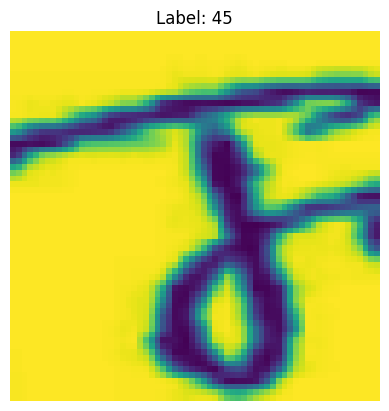

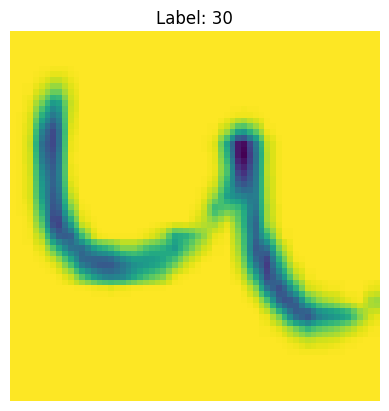

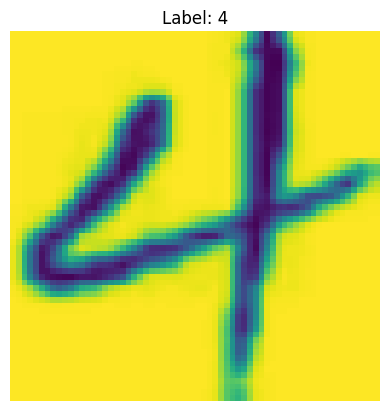

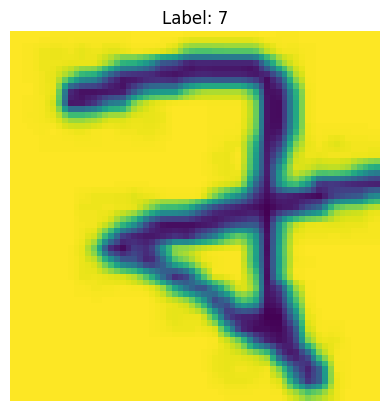

In [239]:
# plot image with its label
import matplotlib.pyplot as plt
def imshow(img, label):
    img = img  # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.title(f"Label: {label}")
    plt.axis('off')
    plt.show()
# Afficher les 4 premières images du batch avec leurs labels
for i in range(4):
    imshow(images[i], labels[i].item()) 

## CNN simple avec PyTorch

In [3]:
import torch.nn as nn
import torch.nn.functional as F

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=33):
        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3,stride=1, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(2, 2)
        
        
        self.conv4 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.relu4 = nn.ReLU()
        self.pool4 = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))  # [B, 32, 32, 32]
        x = self.pool2(self.relu2(self.conv2(x)))  # [B, 64, 16, 16]
        x = self.pool3(self.relu3(self.conv3(x)))  # [B, 64, 8, 8]
        x = self.pool4(self.relu4(self.conv4(x)))  # [B, 128, 4, 4]

        x = x.view(x.size(0), -1)

        x = self.relu1(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleCNN(num_classes=33).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [6]:
model

SimpleCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu4): ReLU()
  (pool4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=33, bias=True)
)

In [69]:
from sklearn.metrics import accuracy_score


  the number of the visualisation is not enoth  so the solution is to augment the data set with a this data set but zith rotation and even some torssion 

In [276]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

labels = [label for _, label in dataset.samples]

indices = list(range(len(dataset)))

train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

temp_labels = [labels[i] for i in temp_indices]

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.5,
    stratify=temp_labels,
    random_state=42
)

train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)
test_dataset = Subset(dataset, test_indices)


train_loader = DataLoader(
    train_dataset,
    batch_size=350,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=350,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=350,
    shuffle=False,
    num_workers=2
)

In [277]:
num_epochs = 50

train_loss_list = []
valid_loss_list = []

model.to(device)

for epoch in range(num_epochs):

    # ======================
    # Training
    # ======================
    model.train()
    train_loss = 0.0

    for i, data in enumerate(train_loader):
        images, labels = data

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    train_loss_list.append(avg_train_loss)

    # ======================
    # Validation
    # ======================
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for i, data in enumerate(val_loader):
            images, labels = data

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    valid_loss_list.append(avg_val_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}]")
    print(f"Training loss   : {avg_train_loss:.4f}")
    print(f"Validation loss : {avg_val_loss:.4f}")
    print("-" * 30)

Epoch [1/50]
Training loss   : 0.9301
Validation loss : 0.5852
------------------------------
Epoch [2/50]
Training loss   : 0.6414
Validation loss : 0.3419
------------------------------
Epoch [3/50]
Training loss   : 0.4637
Validation loss : 0.3038
------------------------------
Epoch [4/50]
Training loss   : 0.3808
Validation loss : 0.4132
------------------------------
Epoch [5/50]
Training loss   : 0.2912
Validation loss : 0.3439
------------------------------
Epoch [6/50]
Training loss   : 0.2506
Validation loss : 0.4241
------------------------------
Epoch [7/50]
Training loss   : 0.2386
Validation loss : 0.3411
------------------------------
Epoch [8/50]
Training loss   : 0.2010
Validation loss : 0.3970
------------------------------
Epoch [9/50]
Training loss   : 0.1568
Validation loss : 0.4157
------------------------------
Epoch [10/50]
Training loss   : 0.1409
Validation loss : 0.4395
------------------------------
Epoch [11/50]
Training loss   : 0.1353
Validation loss : 0.

In [278]:
from sklearn.metrics import accuracy_score

model.eval()

predictions = []
true_labels = []

with torch.no_grad():
    for i, data in enumerate(test_loader):
        images, labels = data

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        predictions.extend(predicted.cpu().tolist())
        true_labels.extend(labels.cpu().tolist())

accuracy = accuracy_score(true_labels, predictions)

print("Test accuracy :", accuracy)

#torch.save(model.state_dict(), "exammodel.pt")

Test accuracy : 0.9326241134751773


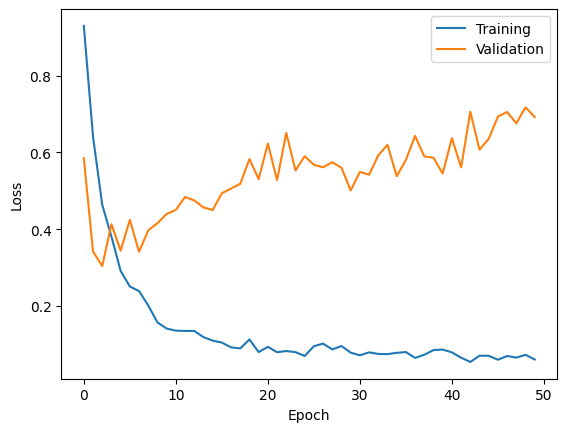

In [279]:
plt.plot(range(len(train_loss_list)),train_loss_list, label='Training')    
plt.plot(range(len(valid_loss_list)),valid_loss_list, label='Validation')    
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
#plt.ylim([0, 0.01])
plt.show()

In [7]:
#test with real digits

path_dataset_test = "/home/ariouich/Bureau/valencia/original_dataset/images_test/digits_splits"

In [8]:
class TestDataset(Dataset):
    def __init__(self, dataset_path, transform=None):
        self.dataset_path = dataset_path
        self.transform = transform
        self.samples = []

        for filename in os.listdir(dataset_path):
            if filename.lower().endswith((".png", ".jpg", ".jpeg")):
                image_path = os.path.join(dataset_path, filename)
                label = int(filename.split("_")[0].split(".")[0])
                print(f"Label extrait : {label}")  # Extraire le label à partir du nom de fichier
                self.samples.append((image_path, label))

        print(f"Nombre total d'images chargées : {len(self.samples)}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, label = self.samples[idx]

        image = Image.open(image_path).convert("L")  # Convertir en niveaux de gris

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(label, dtype=torch.long)

        return image, label
    

test_dataset = TestDataset(
    dataset_path=path_dataset_test
)

Label extrait : 7
Label extrait : 7
Label extrait : 9
Label extrait : 9
Label extrait : 4
Label extrait : 4
Label extrait : 5
Label extrait : 4
Label extrait : 8
Nombre total d'images chargées : 9


In [85]:
[label for _, label in test_dataset.samples]

[0, 1, 2, 1, 1, 2, 1, 1, 3]

In [9]:
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import argparse

In [10]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes: int = 62):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 64 -> 32

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 -> 16

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 16 -> 8
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [20]:
model = SmallCNN(num_classes=33)
checkpoint = torch.load("/home/ariouich/Bureau/valencia/Madrina/AsistenteWebTFGBackendAIModule/data/handwriting_dataset_code/checkpoints/best_model.pt", map_location="cpu")
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=8192, out_features=256, bias

Label extrait : 7
Label extrait : 7
Label extrait : 9
Label extrait : 9
Label extrait : 4
Label extrait : 4
Label extrait : 5
Label extrait : 4
Label extrait : 8
Nombre total d'images chargées : 9


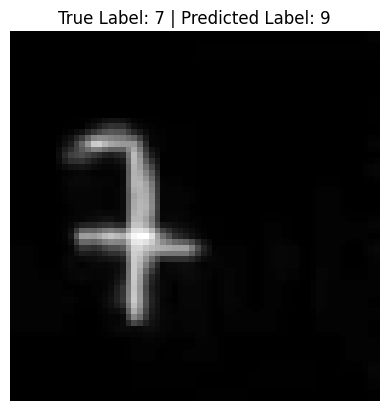

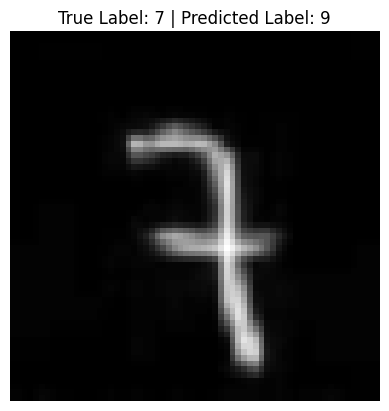

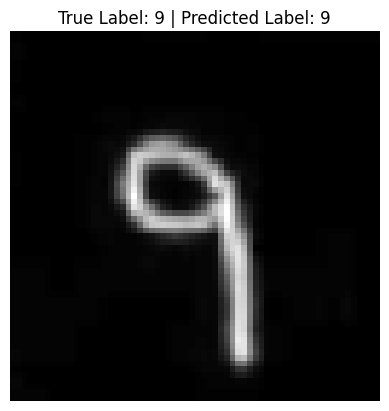

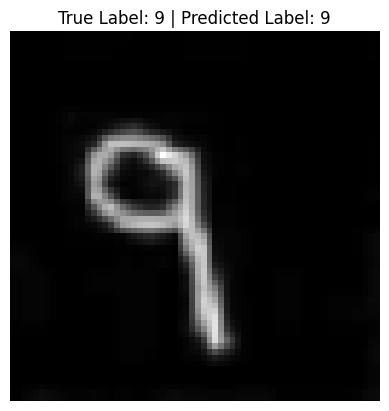

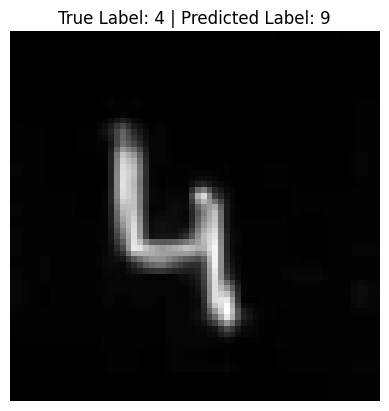

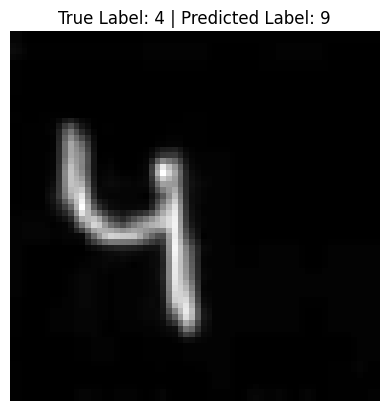

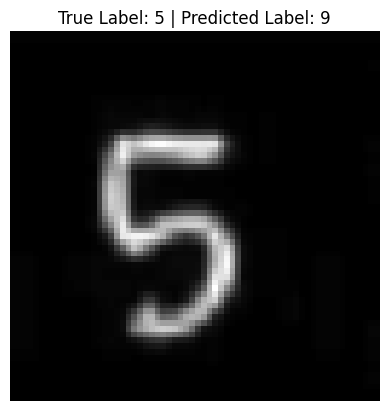

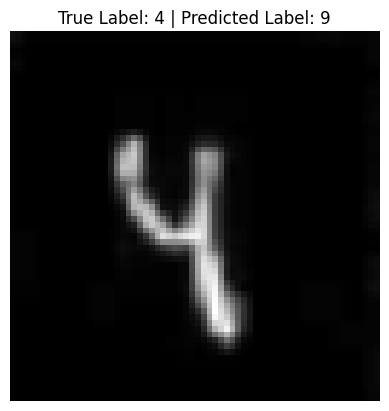

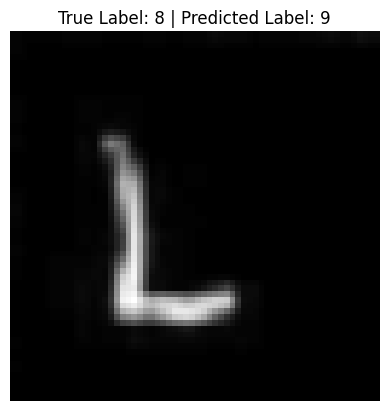

NameError: name 'accuracy_score' is not defined

In [21]:
# test the model on the test dataset 
# plot the image with its predicted label and its true label
import matplotlib.pyplot as plt
def imshow(img, true_label, predicted_label):
    img = img  # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)), cmap='gray')
    plt.title(f"True Label: {true_label} | Predicted Label: {predicted_label}")
    plt.axis('off')
    plt.show()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)
predictions = []
true_labels = []
with torch.no_grad():
    # test the model on the test dataset 
    # plot the image with its predicted label and its true label
    import matplotlib.pyplot as plt
    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),  # convertit en tensor et normalise entre 0 et 1
    ])

    # Recreate test_dataset with the same transform used for training/validation
    test_dataset = TestDataset(dataset_path=path_dataset_test, transform=transform)

    def imshow(img, true_label, predicted_label):
        npimg = img.cpu().numpy()
        plt.imshow(np.transpose(npimg, (1, 2, 0)), cmap='gray')
        plt.title(f"True Label: {true_label} | Predicted Label: {predicted_label}")
        plt.axis('off')
        plt.show()
        
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)
    predictions = []
    true_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            model = model.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            predictions.extend(predicted.cpu().tolist())
            true_labels.extend(labels.cpu().tolist())

            imshow(images[0], labels[0].item(), predicted[0].item())

    accuracy = accuracy_score(true_labels, predictions)
    print("Test accuracy :", accuracy)
        

Predicted labels for test images: [1, 1, 1, 1, 1, 1, 1, 1, 1]


NameError: name 'unique_map_leabels' is not defined

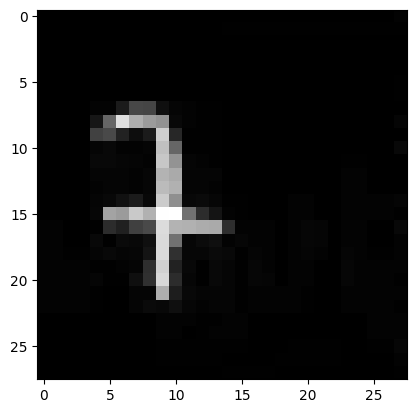

In [18]:
#load the image in the path and predict the label with the model
from PIL import Image
import os

def predict_image(image_path, model, transform, device):
    model.eval()

    image = Image.open(image_path).convert("L")

    if transform:
        image = transform(image)

    image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image)
        _, predicted = torch.max(output, 1)

    return predicted.item()


# Parcourir les images dans le dossier de test et faire des prédictions
test_images = []
predicted_labels = []
for filename in os.listdir(path_dataset_test):
    if filename.lower().endswith((".png", ".jpg", ".jpeg")):
        image_path = os.path.join(path_dataset_test, filename)
        predicted_label = predict_image(image_path, model, transform, device)
        test_images.append(image_path)
        predicted_labels.append(predicted_label)

print(f"Predicted labels for test images: {predicted_labels}")
    
# Afficher les résultats
for image_path, label in zip(test_images, predicted_labels):
    plt.imshow(Image.open(image_path).convert("L"), cmap='gray')
    label_ref = unique_map_leabels[label]
    plt.title(f"Predicted Label: {label_ref}")
    plt.axis('off')
    plt.show()
    